# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Maria Putu Evelyne Corena Puryatma | 5054251011 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **TensorFlow / Keras** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan tf.keras.utils.set_random_seed(42).

import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

tf.keras.utils.set_random_seed(42)
print('Versi TensorFlow:', tf.__version__)

Versi TensorFlow: 2.20.0


In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv('Churn_Modelling.csv')
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
print('Jumlah baris dan kolom:', df.shape)
df.info()

Jumlah baris dan kolom: (10000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [4]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [5]:
print('Jumlah missing value per kolom:')
print(df.isnull().sum())
print('\nJumlah baris duplikat:', df.duplicated().sum())

Jumlah missing value per kolom:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Jumlah baris duplikat: 0


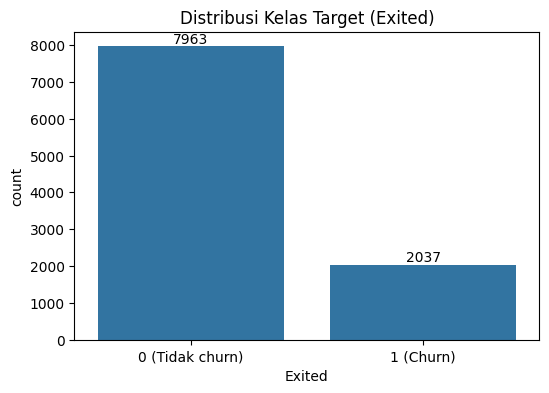

Proporsi tiap kelas:
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


In [6]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Exited', data=df)
ax.bar_label(ax.containers[0])
plt.title('Distribusi Kelas Target (Exited)')
plt.xticks([0, 1], ['0 (Tidak churn)', '1 (Churn)'])
plt.show()

print('Proporsi tiap kelas:')
print(df['Exited'].value_counts(normalize=True).round(4))

Datasetnya imbalanced: 79.6% nasabah tidak churn dan cuma 20.4% yang churn (kira-kira 4:1). Jadi accuracy saja tidak cukup, perlu lihat precision, recall, dan F1 juga.

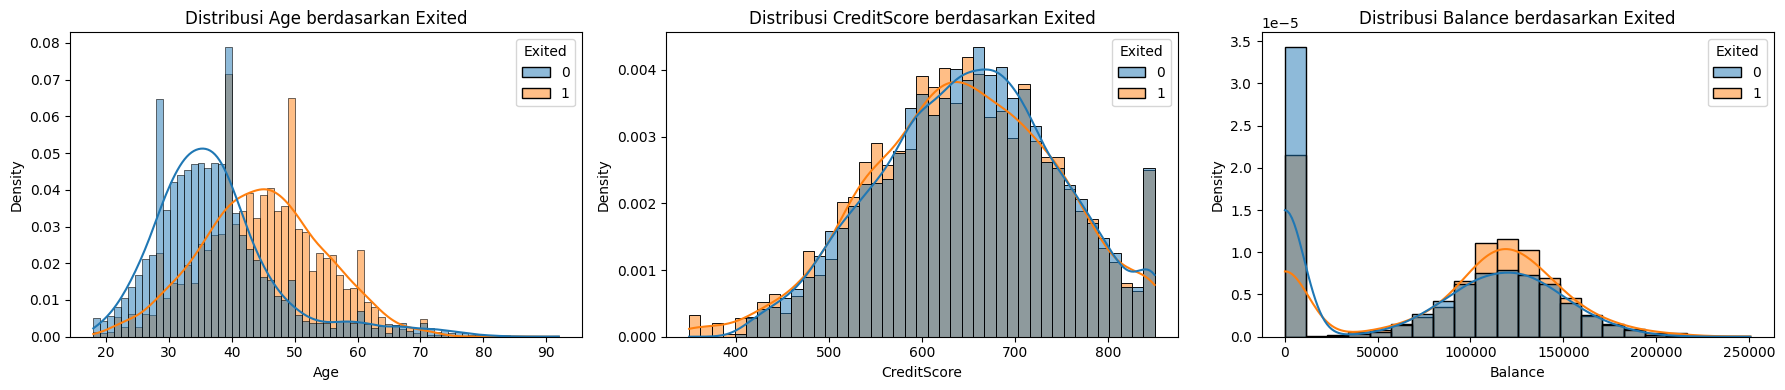

         Age        CreditScore         Balance          
        mean median        mean median     mean    median
Exited                                                   
0       37.4   36.0       651.9  653.0  72745.3   92072.7
1       44.8   45.0       645.4  646.0  91108.5  109349.3


In [7]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

fitur_numerik = ['Age', 'CreditScore', 'Balance']
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, fitur_numerik):
    # common_norm=False supaya tiap kelas dinormalisasi sendiri (kelas churn jauh lebih sedikit)
    sns.histplot(data=df, x=col, hue='Exited', kde=True, stat='density', common_norm=False, ax=ax)
    ax.set_title(f'Distribusi {col} berdasarkan Exited')
plt.tight_layout()
plt.show()

# Rata-rata dan median tiap fitur untuk nasabah yang churn dan tidak
print(df.groupby('Exited')[fitur_numerik].agg(['mean', 'median']).round(1))

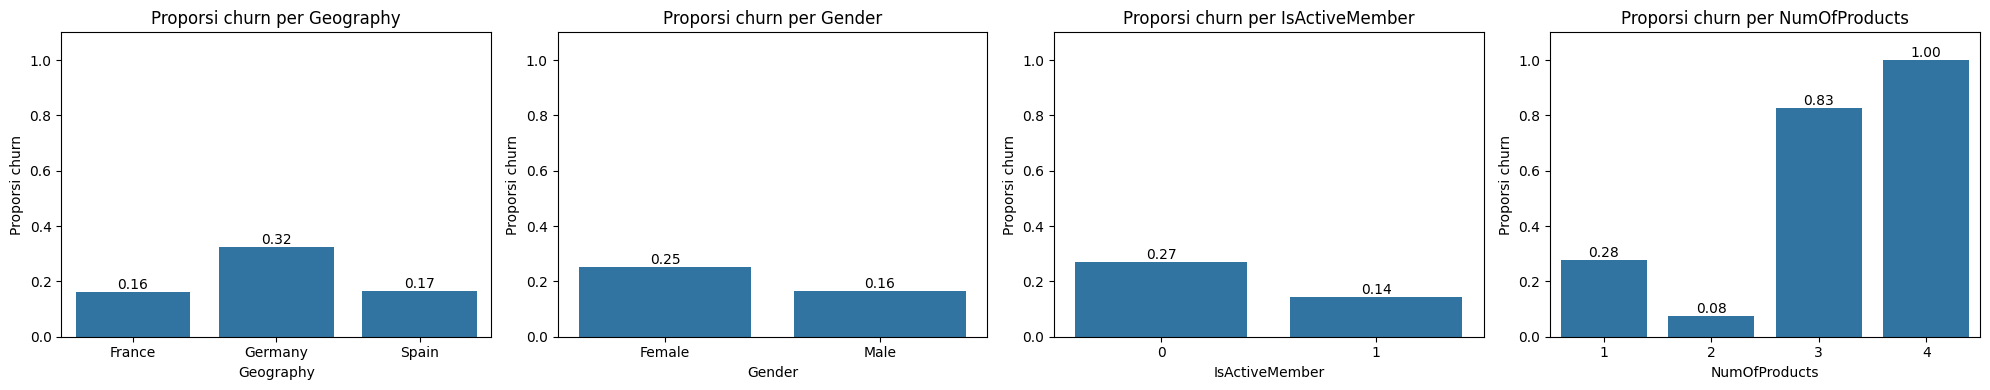

           jumlah  proporsi_churn
Geography                        
France       5014           0.162
Germany      2509           0.324
Spain        2477           0.167 

        jumlah  proporsi_churn
Gender                        
Female    4543           0.251
Male      5457           0.165 

                jumlah  proporsi_churn
IsActiveMember                        
0                 4849           0.269
1                 5151           0.143 

               jumlah  proporsi_churn
NumOfProducts                        
1                5084           0.277
2                4590           0.076
3                 266           0.827
4                  60           1.000 



In [8]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

fitur_kategorik = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, fitur_kategorik):
    proporsi = df.groupby(col)['Exited'].mean()
    sns.barplot(x=proporsi.index.astype(str), y=proporsi.values, ax=ax)
    ax.bar_label(ax.containers[0], fmt='%.2f')
    ax.set_title(f'Proporsi churn per {col}')
    ax.set_ylabel('Proporsi churn')
    ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.show()

# Jumlah nasabah tiap kategori, supaya tahu proporsinya dihitung dari berapa orang
for col in fitur_kategorik:
    print(df.groupby(col)['Exited'].agg(jumlah='size', proporsi_churn='mean').round(3), '\n')

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

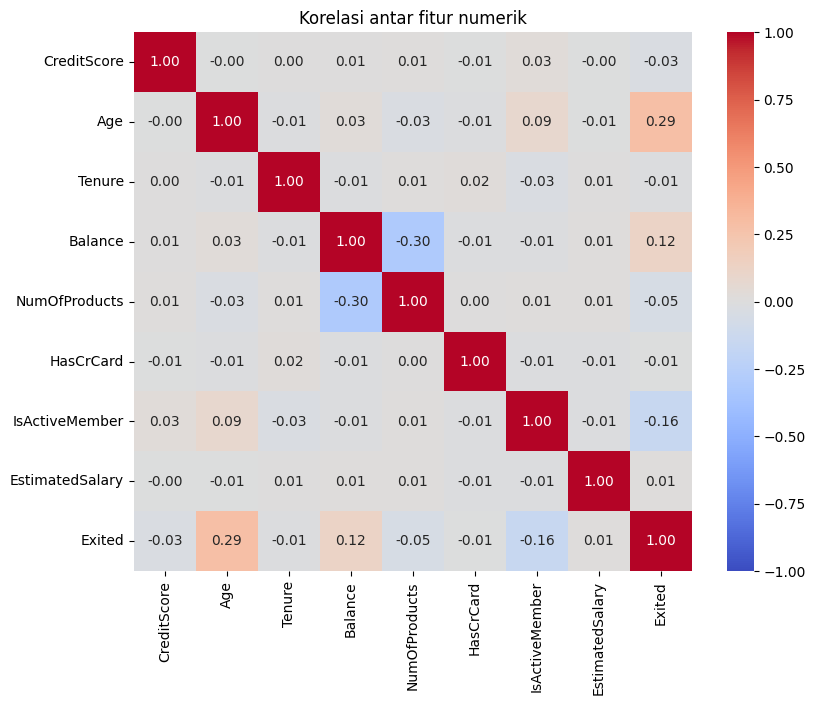

In [9]:
# Korelasi antar fitur numerik dan target
kolom_angka = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
               'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
plt.figure(figsize=(9, 7))
sns.heatmap(df[kolom_angka].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Korelasi antar fitur numerik')
plt.show()

In [10]:
# Di histogram Balance ada batang tinggi di angka 0, cek berapa banyak nasabah yang saldonya 0
saldo_nol = df['Balance'] == 0
print('Jumlah nasabah dengan Balance = 0:', saldo_nol.sum(), f'({saldo_nol.mean() * 100:.1f}%)')
print('Proporsi churn kalau Balance = 0:', round(df.loc[saldo_nol, 'Exited'].mean(), 3))
print('Proporsi churn kalau Balance > 0:', round(df.loc[~saldo_nol, 'Exited'].mean(), 3))

Jumlah nasabah dengan Balance = 0: 3617 (36.2%)
Proporsi churn kalau Balance = 0: 0.138
Proporsi churn kalau Balance > 0: 0.241


1. Tidak ada missing value dan tidak ada baris duplikat.
2. Nasabah yang churn rata-rata lebih tua (median 45 tahun) dibanding yang tidak churn (median 36 tahun). Age juga punya korelasi paling besar dengan Exited (0.29).
3. CreditScore hampir tidak ada bedanya antara yang churn dan tidak, distribusinya numpuk.
4. 36.2% nasabah saldonya 0. Yang saldonya 0 malah lebih jarang churn (13.8%) dibanding yang punya saldo (24.1%).
5. Churn paling tinggi di Germany (32%), nasabah perempuan (25%), dan nasabah yang tidak aktif (27%).
6. Nasabah dengan 2 produk paling jarang churn (7.6%), sedangkan yang punya 3–4 produk hampir semuanya churn (83% dan 100%), tapi jumlah orangnya sedikit (266 dan 60).
7. Korelasi antar fitur kecil semua, yang agak kelihatan cuma Balance dengan NumOfProducts (-0.30).

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [11]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# RowNumber  : cuma nomor urut baris
# CustomerId : cuma ID nasabah, tiap orang beda
# Surname    : nama belakang, tidak ada hubungannya dengan churn
# Ketiganya cuma identitas, jadi tidak membantu model belajar pola churn.
df_model = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
df_model.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [12]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df_model.drop(columns='Exited')
y = df_model['Exited']

# 70% train, sisanya 30% dibagi dua jadi 15% validation dan 15% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

for nama, X_set, y_set in [('Train', X_train, y_train), ('Validation', X_val, y_val), ('Test', X_test, y_test)]:
    print(f'{nama}: {X_set.shape}, proporsi churn = {y_set.mean():.3f}')

Train: (7000, 10), proporsi churn = 0.204
Validation: (1500, 10), proporsi churn = 0.204
Test: (1500, 10), proporsi churn = 0.203


In [13]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

kolom_onehot = ['Geography']
kolom_biner = ['Gender']
kolom_numerik = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
# HasCrCard dan IsActiveMember sudah 0/1, jadi dibiarkan apa adanya (passthrough)

preprocessor = ColumnTransformer([
    ('geo', OneHotEncoder(sparse_output=False), kolom_onehot),
    ('gender', OneHotEncoder(drop='if_binary', sparse_output=False), kolom_biner),  # Female=0, Male=1
    ('num', StandardScaler(), kolom_numerik),
], remainder='passthrough')

# fit hanya di train set, lalu transform ke semua set
X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

nama_fitur = preprocessor.get_feature_names_out()
print('Jumlah fitur setelah preprocessing:', len(nama_fitur))
print(nama_fitur)

Jumlah fitur setelah preprocessing: 12
['geo__Geography_France' 'geo__Geography_Germany' 'geo__Geography_Spain'
 'gender__Gender_Male' 'num__CreditScore' 'num__Age' 'num__Tenure'
 'num__Balance' 'num__NumOfProducts' 'num__EstimatedSalary'
 'remainder__HasCrCard' 'remainder__IsActiveMember']


In [14]:
# Pastikan X dan y untuk train, validation, dan test berupa numpy array bertipe float32.
# Contoh: X_train = np.asarray(X_train, dtype="float32")

X_train = np.asarray(X_train, dtype='float32')
X_val = np.asarray(X_val, dtype='float32')
X_test = np.asarray(X_test, dtype='float32')
y_train = np.asarray(y_train, dtype='float32')
y_val = np.asarray(y_val, dtype='float32')
y_test = np.asarray(y_test, dtype='float32')

print('X_train:', X_train.shape, X_train.dtype, '| y_train:', y_train.shape, y_train.dtype)
print('X_val  :', X_val.shape, X_val.dtype, '| y_val  :', y_val.shape, y_val.dtype)
print('X_test :', X_test.shape, X_test.dtype, '| y_test :', y_test.shape, y_test.dtype)

X_train: (7000, 12) float32 | y_train: (7000,) float32
X_val  : (1500, 12) float32 | y_val  : (1500,) float32
X_test : (1500, 12) float32 | y_test : (1500,) float32


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [15]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train, y_train)

pred_logreg = logreg.predict(X_test)
proba_logreg = logreg.predict_proba(X_test)[:, 1]
print('Accuracy Logistic Regression di test set:', round(accuracy_score(y_test, pred_logreg), 4))

Accuracy Logistic Regression di test set: 0.8153


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer**. Karena ini klasifikasi biner, gunakan **1 neuron output dengan aktivasi Sigmoid** dan **Binary Cross-Entropy** sebagai loss function.

Contoh arsitektur: `Input → Dense(16, ReLU) → Dense(1, Sigmoid)`

In [16]:
# Definisikan arsitektur ANN sederhana menggunakan keras.Sequential.
# Gunakan keras.Input(shape=(jumlah_fitur,)) sebagai layer pertama, lalu layers.Dense untuk hidden layer dan output layer.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().

n_fitur = X_train.shape[1]

model_ann1 = keras.Sequential([
    keras.Input(shape=(n_fitur,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])
model_ann1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Compile model: tentukan optimizer (misalnya keras.optimizers.Adam(learning_rate=...)), loss="binary_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit(), gunakan validation_data=(X_val, y_val) agar loss dan accuracy validation tercatat setiap epoch.
# Simpan hasil model.fit() ke variabel history.

EPOCHS = 50
BATCH_SIZE = 32

model_ann1.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='binary_crossentropy', metrics=['accuracy'])

history_ann1 = model_ann1.fit(X_train, y_train, validation_data=(X_val, y_val),
                              epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0)

# verbose=0 supaya output tidak kepanjangan, jadi hasil epoch terakhir dicetak manual
def cetak_epoch_terakhir(history):
    h = history.history
    print(f"Epoch terakhir -> loss: {h['loss'][-1]:.4f}, accuracy: {h['accuracy'][-1]:.4f}, "
          f"val_loss: {h['val_loss'][-1]:.4f}, val_accuracy: {h['val_accuracy'][-1]:.4f}")
    print(f"val_loss paling rendah: {min(h['val_loss']):.4f} (epoch {np.argmin(h['val_loss']) + 1})")

cetak_epoch_terakhir(history_ann1)

Epoch terakhir -> loss: 0.3396, accuracy: 0.8591, val_loss: 0.3258, val_accuracy: 0.8620
val_loss paling rendah: 0.3258 (epoch 50)


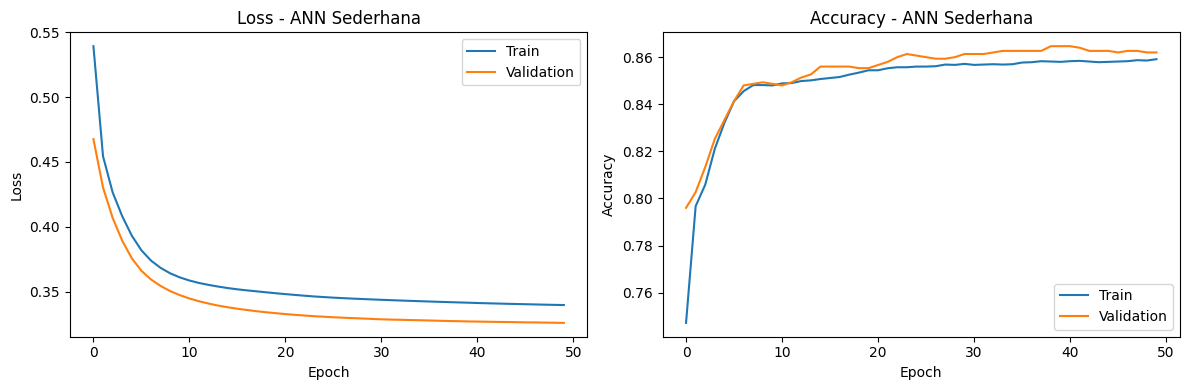

In [18]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot.
# Gunakan history.history["loss"], history.history["val_loss"], history.history["accuracy"], dan history.history["val_accuracy"].

def plot_learning_curve(history, judul):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h['loss'], label='Train')
    axes[0].plot(h['val_loss'], label='Validation')
    axes[0].set_title(f'Loss - {judul}')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[1].plot(h['accuracy'], label='Train')
    axes[1].plot(h['val_accuracy'], label='Validation')
    axes[1].set_title(f'Accuracy - {judul}')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_learning_curve(history_ann1, 'ANN Sederhana')

Loss train dan validation sama-sama turun lalu mendatar setelah sekitar epoch 20, dan garisnya berdekatan. Tidak ada tanda overfitting.

In [19]:
# Lakukan prediksi pada test set dengan model.predict(X_test). Hasilnya berupa probabilitas kelas 1.
# Ubah menjadi label dengan threshold 0.5, lalu simpan probabilitas dan label untuk keperluan evaluasi.

proba_ann1 = model_ann1.predict(X_test, verbose=0).ravel()
pred_ann1 = (proba_ann1 >= 0.5).astype(int)
print('Contoh probabilitas:', proba_ann1[:5].round(3))
print('Contoh label       :', pred_ann1[:5])

Contoh probabilitas: [0.207 0.025 0.038 0.071 0.203]
Contoh label       : [0 0 0 0 0]


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [20]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan layers.Dropout(rate) di antara hidden layer.
# Tampilkan ringkasan model beserta jumlah parameternya.

model_ann2 = keras.Sequential([
    keras.Input(shape=(n_fitur,)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])
model_ann2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch terakhir -> loss: 0.3366, accuracy: 0.8636, val_loss: 0.3180, val_accuracy: 0.8713
val_loss paling rendah: 0.3156 (epoch 42)


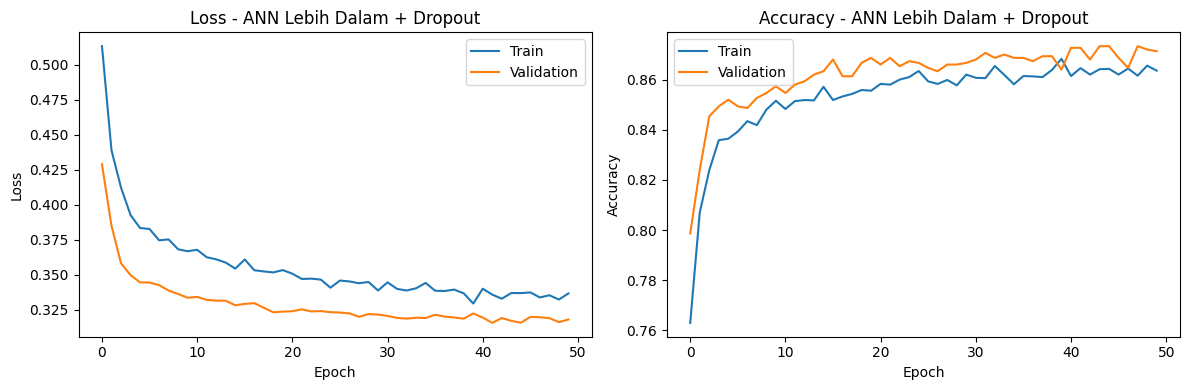

In [21]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

model_ann2.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='binary_crossentropy', metrics=['accuracy'])

history_ann2 = model_ann2.fit(X_train, y_train, validation_data=(X_val, y_val),
                              epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0)

cetak_epoch_terakhir(history_ann2)
plot_learning_curve(history_ann2, 'ANN Lebih Dalam + Dropout')

1. Tidak ada tanda overfitting. Val loss terus turun sampai 0.318 dan tidak naik lagi, malah lebih rendah dari train loss (0.337).
2. Train loss lebih tinggi dari val loss karena Dropout cuma aktif waktu training, jadi waktu training modelnya "dipersulit".
3. Dibanding model 3.2, kurvanya lebih naik-turun (tidak semulus 3.2) karena neuron yang dimatikan Dropout beda-beda tiap batch. Val accuracy-nya sedikit lebih tinggi (0.871 vs 0.862).

In [22]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

proba_ann2 = model_ann2.predict(X_test, verbose=0).ravel()
pred_ann2 = (proba_ann2 >= 0.5).astype(int)

## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [23]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung bobot setiap kelas berdasarkan train set, misalnya dengan sklearn.utils.class_weight.compute_class_weight("balanced", ...).
# Masukkan ke model.fit() melalui parameter class_weight={0: bobot_kelas_0, 1: bobot_kelas_1}.

# Arsitektur yang dipakai: ANN lebih dalam + Dropout dari 3.3, karena di validation set
# val_loss-nya lebih rendah (0.318 vs 0.326) dan val_accuracy-nya lebih tinggi (0.871 vs 0.862).
model_ann3 = keras.Sequential([
    keras.Input(shape=(n_fitur,)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])

bobot = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight = {0: bobot[0], 1: bobot[1]}
print('Class weight:', {k: round(float(v), 3) for k, v in class_weight.items()})

model_ann3.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='binary_crossentropy', metrics=['accuracy'])

history_ann3 = model_ann3.fit(X_train, y_train, validation_data=(X_val, y_val),
                              epochs=EPOCHS, batch_size=BATCH_SIZE,
                              class_weight=class_weight, verbose=0)
cetak_epoch_terakhir(history_ann3)

Class weight: {0: 0.628, 1: 2.454}
Epoch terakhir -> loss: 0.4401, accuracy: 0.8039, val_loss: 0.4200, val_accuracy: 0.8000
val_loss paling rendah: 0.4150 (epoch 48)


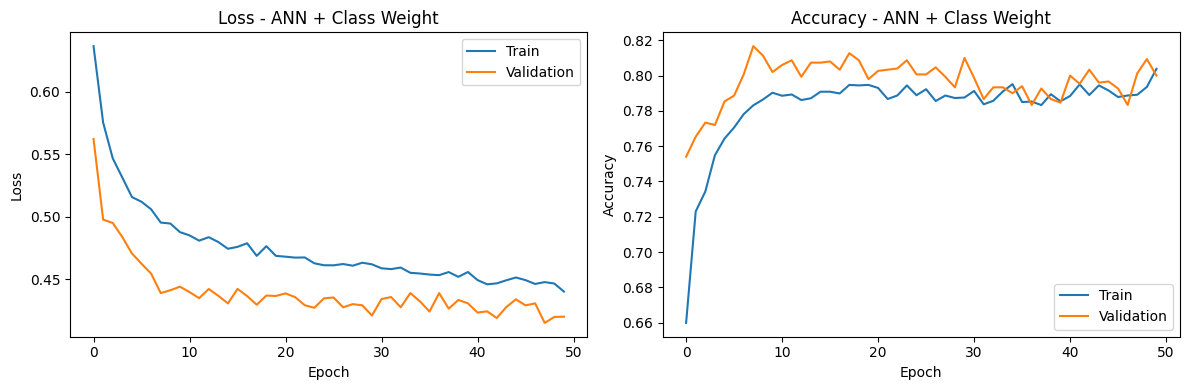

In [24]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

plot_learning_curve(history_ann3, 'ANN + Class Weight')

proba_ann3 = model_ann3.predict(X_test, verbose=0).ravel()
pred_ann3 = (proba_ann3 >= 0.5).astype(int)

Loss-nya lebih tinggi (0.44) dibanding model tanpa class weight karena kesalahan di kelas churn sekarang dihitung ±2.45 kali lebih berat. Val accuracy turun ke sekitar 0.80 dan lebih naik-turun, tapi tidak ada tanda overfitting.

# 4. Evaluasi Model

In [25]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

hasil_model = {
    'Logistic Regression': (pred_logreg, proba_logreg),
    'ANN Sederhana': (pred_ann1, proba_ann1),
    'ANN Dalam + Dropout': (pred_ann2, proba_ann2),
    'ANN + Class Weight': (pred_ann3, proba_ann3),
}

rows = []
for nama, (pred, proba) in hasil_model.items():
    rows.append({
        'model': nama,
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1_score': f1_score(y_test, pred),
    })

# precision, recall, dan f1 dihitung untuk kelas 1 (churn)
tabel_evaluasi = pd.DataFrame(rows).set_index('model').round(4)
tabel_evaluasi

,accuracy,precision,recall,f1_score
model,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092
ANN Sederhana,0.8633,0.7577,0.4820,0.5892
ANN Dalam + Dropout,0.8640,0.7988,0.4426,0.5696
ANN + Class Weight,0.7907,0.4905,0.7607,0.5964


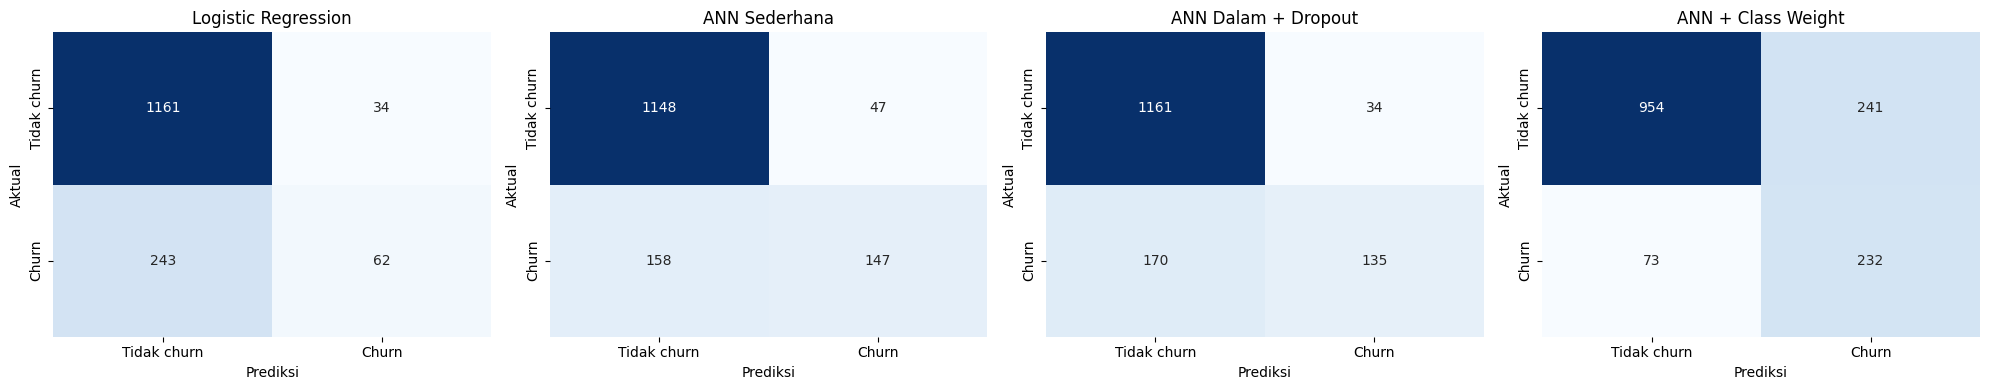

In [26]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (nama, (pred, proba)) in zip(axes, hasil_model.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Tidak churn', 'Churn'], yticklabels=['Tidak churn', 'Churn'])
    ax.set_title(nama)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
plt.tight_layout()
plt.show()

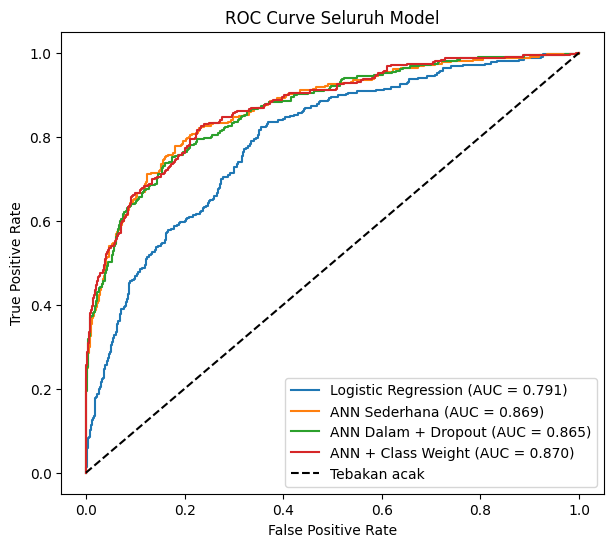

In [27]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(7, 6))
for nama, (pred, proba) in hasil_model.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{nama} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Tebakan acak')
plt.title('ROC Curve Seluruh Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

AUC ketiga ANN hampir sama (0.865–0.870) dan semuanya di atas Logistic Regression (0.791).

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

1. **Logistic Regression vs ANN.** Logistic Regression accuracy-nya 0.815, kelihatannya lumayan, tapi recall churn cuma 0.203 (dari 305 nasabah churn di test set, yang ketebak cuma 62). Jadi accuracy-nya tinggi karena kebanyakan menebak "tidak churn". Semua ANN lebih bagus: accuracy 0.863–0.864 dan AUC 0.865–0.870 (Logistic Regression 0.791). Ini karena ANN bisa menangkap pola non-linear, misalnya churn paling rendah di 2 produk tapi tinggi di 1 dan 3–4 produk, pola seperti ini tidak bisa ditangkap garis lurus.
2. **Learning curve.** Ketiga ANN tidak ada yang overfitting, val loss tidak pernah naik lagi dan selalu di bawah train loss. Juga tidak underfitting karena hasilnya lebih bagus dari baseline. ANN sederhana kurvanya paling mulus dan sudah mendatar sekitar epoch 20.
3. **Pengaruh tambah layer dan Dropout.** Parameternya naik dari 225 jadi 3.457, tapi hasilnya hampir sama saja: accuracy 0.864 vs 0.863, precision naik (0.799 vs 0.758) tapi recall turun (0.443 vs 0.482), F1 malah sedikit turun (0.570 vs 0.589). Jadi untuk data tabular 12 fitur ini, 1 hidden layer sudah cukup. Dropout membuat train loss lebih tinggi dari val loss dan kurvanya lebih naik-turun.
4. **Pengaruh class weight.** Recall churn naik jauh dari 0.443 jadi 0.761 (232 dari 305 nasabah churn ketebak), tapi precision turun dari 0.799 jadi 0.491 karena false positive naik dari 34 jadi 241. Accuracy ikut turun jadi 0.791. F1-nya paling tinggi (0.596) dan AUC-nya tetap (0.870), artinya kemampuan model membedakan kelasnya sama saja, yang berubah cuma model jadi lebih gampang menebak "churn".
5. **Model mana yang dipilih?** Tergantung tujuannya. Kalau bank mau menangkap sebanyak mungkin nasabah yang akan churn (misalnya untuk dikasih promo), pakai ANN + class weight karena recall-nya paling tinggi. Kalau tidak mau banyak salah tuduh, pakai ANN tanpa class weight karena precision-nya lebih tinggi.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan**
1. ANN lebih bagus dari Logistic Regression di data ini: accuracy 0.863 vs 0.815 dan AUC 0.87 vs 0.79.
2. ANN yang lebih dalam + Dropout tidak memberi peningkatan yang berarti dibanding ANN sederhana (accuracy 0.864 vs 0.863), padahal parameternya ±15 kali lebih banyak.
3. Karena datanya imbalanced (churn cuma 20.4%), model tanpa class weight recall-nya rendah (0.44–0.48). Class weight menaikkan recall jadi 0.761 dan F1 jadi yang paling tinggi (0.596), tapi precision dan accuracy turun.
4. Tidak ada model yang overfitting selama 50 epoch.

**Saran**
1. Coba ubah threshold (tidak harus 0.5) supaya precision dan recall bisa diatur sesuai kebutuhan.
2. Coba cara lain untuk data imbalanced, misalnya SMOTE atau oversampling.
3. Coba tuning jumlah neuron, learning rate, dan dropout rate, lalu pakai EarlyStopping supaya epoch-nya tidak perlu ditentukan manual.
4. Bandingkan juga dengan model tree seperti Random Forest atau XGBoost, karena di data tabular model seperti itu sering lebih bagus dari ANN.